# Capstone project - Air passengers, start to finish

The course pipeline, on this series: explore it, decompose it, set the
benchmark floor, check what the floor leaves on the table, fit a model
through the framework, cross-validate, and read the result against the
floor.

**What is graded is the process, not the number.** A low MASE from one
holdout with no intervals scores worse than an honest analysis that
concludes the benchmark wins.

Full rules and report requirements: `brief.md`. Grading: `rubric.md`. This
notebook is the first deliverable; it should run top to bottom in under ten
minutes on Colab.

This notebook is a starter. You may swap in your own series or your own
framework - see "Your own data or method" in `brief.md`.

In [1]:
import sys

if "google.colab" in sys.modules:
    !git clone -q https://github.com/lamaalqhtaniit-tech/international-airpassengers-project.git /content/proj
    %cd /content/proj
    !pip install -q -e .

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from coursekit import plotting as P
from coursekit import scoring

P.use_course_style()

SEASON_LENGTH = 12
H = 12            # forecast horizon for cross-validation
H_REPORT = 24     # forecast horizon for the report

/content/proj
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Installing backend dependencies ... done
  Preparing editable metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 501.8/501.8 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.7/348.7 kB 20.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 281.0/281.0 kB 17.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.4/50.4 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.9/59.9 kB 4.0 MB/s eta 0:00:00
  Building editable for international-airpassengers-project (pyproject.toml) ... done


/content/proj/coursekit/plotting.py:599: SyntaxWarning: invalid escape sequence '\h'
  :math:`\hat{F}` whose characteristics do not change over time -- so that a
/content/proj/coursekit/plotting.py:676: SyntaxWarning: invalid escape sequence '\h'
  """Draw the h-step errors :math:`e_{t+h|t} = y_{t+h} - \hat{y}_{t+h|t}`.


---
# 0. The data

Monthly international air passenger numbers, 1949-01 to 1960-12: 144
observations, no gaps. The Box & Jenkins classic (1970) — twelve years of
growth, and a year that does not repeat the same way twice.

Fetched from statsmodels' R-datasets on first run; no download step.

In [2]:
from statsmodels.datasets import get_rdataset

raw = get_rdataset("AirPassengers").data
t = raw["time"].astype(float).to_numpy()
years = np.floor(t).astype(int)
months = np.clip(np.round((t - years) * 12).astype(int) + 1, 1, 12)
df = pd.DataFrame({
    "unique_id": "Air passengers (Box & Jenkins)",
    "ds": pd.to_datetime(pd.Series(years).astype(str) + "-" +
                         pd.Series(months).astype(str).str.zfill(2) + "-01"),
    "y": raw["value"].astype(float),
}).sort_values("ds").reset_index(drop=True)
df.head()

,unique_id,ds,y
0,Air passengers (Box & Jenkins),1949-01-01,112.0
1,Air passengers (Box & Jenkins),1949-02-01,118.0
2,Air passengers (Box & Jenkins),1949-03-01,132.0
3,Air passengers (Box & Jenkins),1949-04-01,129.0
4,Air passengers (Box & Jenkins),1949-05-01,121.0


In [5]:

n_obs = len(df)

range_ = (df["ds"].min(), df["ds"].max())

expected_dates = pd.date_range(
    start=range_[0],
    end=range_[1],
    freq="MS"
)

n_gaps = len(expected_dates.difference(df["ds"]))

print(f"{n_obs} months, {range_[0].date()} to {range_[1].date()}, {n_gaps} gaps")


144 months, 1949-01-01 to 1960-12-01, 0 gaps


I checked the number of observations, the date range, and any missing months to ensure the time series is complete and correctly ordered before forecasting.


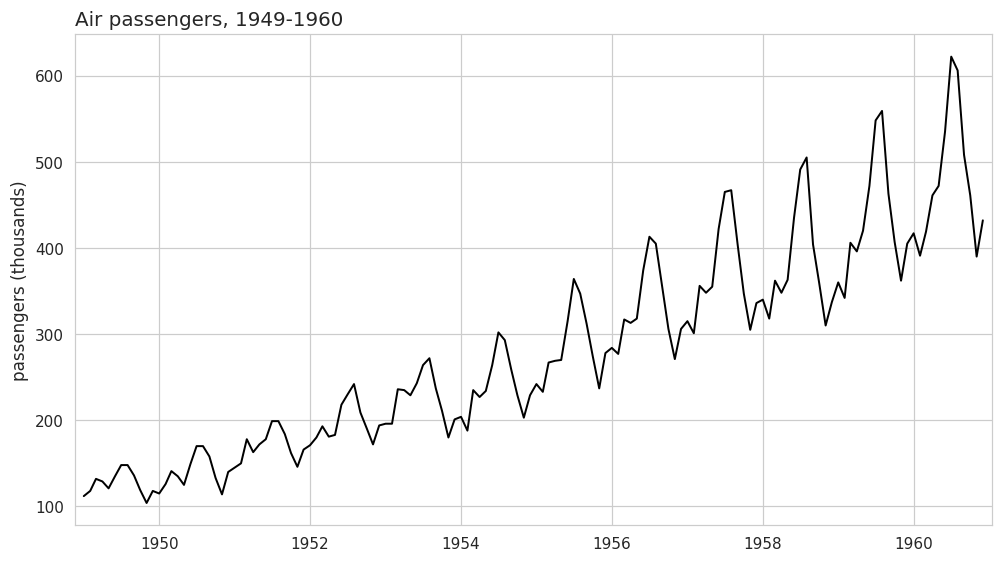

In [6]:
P.plot_series(df, title="Air passengers, 1949-1960",
              ylabel="passengers (thousands)", xlabel="")
plt.show()

**First read.** Before any model, write two sentences that describe this
series in plain language - the kind a non-forecaster could repeat. (Trend?
Seasonality? What happens to the swings as the level grows? Cycle?) These two
sentences belong at the top of your report.

The number of air passengers increases steadily over time, with a seasonal pattern that repeats every year. As passenger numbers grow, the seasonal rises and falls become larger, meaning that the fluctuations increase along with the overall level


---
# 1. Exploration and shape

The Day 1 toolkit, in order. Every chart should carry its claim: a title that
says what it shows, not just "series".

**1.1 Decompose.** STL, additive, period 12. Read all three panels: which
component does the work, and what does the remainder look like?

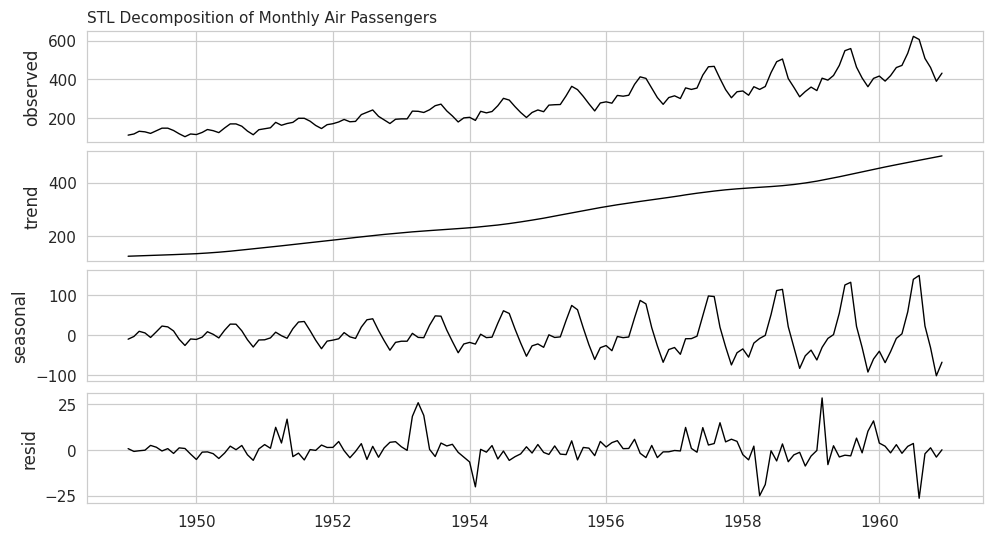

In [9]:

from statsmodels.tsa.seasonal import STL

dcmp = STL(df["y"], period=12, robust=True).fit()

dcmp_df = pd.DataFrame({
    "ds": df["ds"],
    "observed": df["y"],
    "trend": dcmp.trend,
    "seasonal": dcmp.seasonal,
    "resid": dcmp.resid
})

P.decomposition_plot(
    dcmp_df,
    cols=["observed", "trend", "seasonal", "resid"],
    title="STL Decomposition of Monthly Air Passengers",
    x="ds"
)

plt.show()



The **trend** component captures the primary upward movement over time, while the **seasonal** component captures the repeating 12-month pattern whose amplitude grows with the series level. The **remainder (resid)** component looks like irregular fluctuations, with a few noticeable spikes around 1954, 1958, and 1960


**1.2 Trend and seasonal strength.** The two numbers from Day 1, computed
the same way (textbook formulas on the STL components). State what they
imply for model choice.

In [10]:

# Trend and seasonal strength from STL components

trend_strength = max(
    0,
    1 - dcmp.resid.var() / (dcmp.trend + dcmp.resid).var()
)

seasonal_strength = max(
    0,
    1 - dcmp.resid.var() / (dcmp.seasonal + dcmp.resid).var()
)

print(f"trend strength: {trend_strength:.2f}")
print(f"seasonal strength: {seasonal_strength:.2f}")



trend strength: 1.00
seasonal strength: 0.98


The trend strength (1.00) and seasonal strength (0.98) are both very high. This means the data has a clear upward trend and a strong yearly seasonal pattern. The forecasting model should capture both.


**1.3 Autocorrelation.** The ACF of the raw series. What is at lag 12?
At 24? What does that tell you before you fit anything?

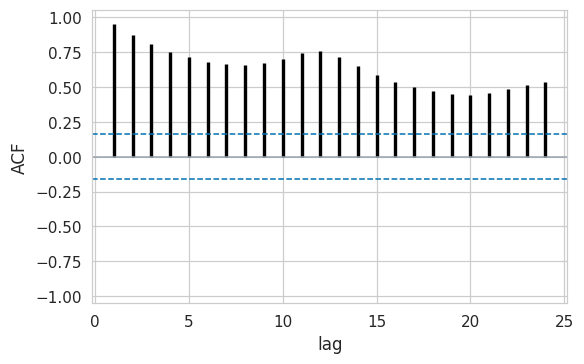

In [12]:

# ACF plot of the raw series, 24 lags
P.acf_plot(df["y"], nlags=24)
plt.show()




**1.3** The ACF decreases slowly, showing a strong trend. There are also high correlations at lags 12 and 24, indicating a repeating yearly seasonal pattern. This suggests that the forecasting model should account for both trend and seasonality.


---
# 2. The floor

The seasonal naive is the first model you fit on any series - not as a
formality, as the thing everything else has to beat. Fit it, check what it
leaves on the table, and give it an honest interval.

In [13]:
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive

floor_sf = StatsForecast(models=[SeasonalNaive(season_length=SEASON_LENGTH)],
                         freq="MS", n_jobs=1)
floor_fc = floor_sf.forecast(df=df, h=H_REPORT, level=scoring.LEVELS)
floor_fc.head()

,unique_id,ds,SeasonalNaive,SeasonalNaive-lo-20,SeasonalNaive-lo-40,SeasonalNaive-lo-60,SeasonalNaive-lo-80,SeasonalNaive-lo-95,SeasonalNaive-hi-20,SeasonalNaive-hi-40,SeasonalNaive-hi-60,SeasonalNaive-hi-80,SeasonalNaive-hi-95
0,Air passengers (Box & Jenkins),1961-01-01,417.0,407.799511,397.956005,386.435898,370.4595,345.822448,426.200489,436.043995,447.564102,463.5405,488.177552
1,Air passengers (Box & Jenkins),1961-02-01,391.0,381.799511,371.956005,360.435898,344.4595,319.822448,400.200489,410.043995,421.564102,437.5405,462.177552
2,Air passengers (Box & Jenkins),1961-03-01,419.0,409.799511,399.956005,388.435898,372.4595,347.822448,428.200489,438.043995,449.564102,465.5405,490.177552
3,Air passengers (Box & Jenkins),1961-04-01,461.0,451.799511,441.956005,430.435898,414.4595,389.822448,470.200489,480.043995,491.564102,507.5405,532.177552
4,Air passengers (Box & Jenkins),1961-05-01,472.0,462.799511,452.956005,441.435898,425.4595,400.822448,481.200489,491.043995,502.564102,518.5405,543.177552


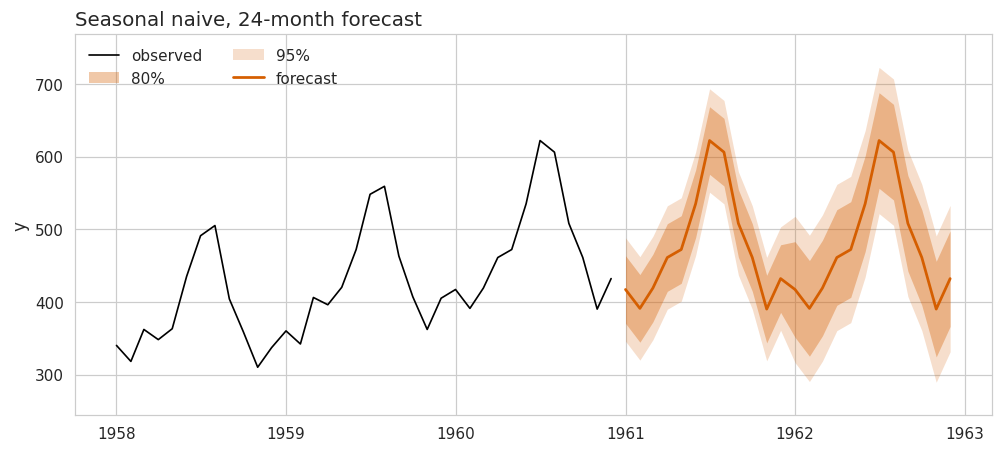

In [14]:
P.fan_chart(df, floor_fc.rename(columns={
            "SeasonalNaive": "mean",
            "SeasonalNaive-lo-20": "lo-20",
            "SeasonalNaive-lo-40": "lo-40",
            "SeasonalNaive-lo-60": "lo-60",
            "SeasonalNaive-lo-80": "lo-80",
            "SeasonalNaive-lo-95": "lo-95",
            "SeasonalNaive-hi-20": "hi-20",
            "SeasonalNaive-hi-40": "hi-40",
            "SeasonalNaive-hi-60": "hi-60",
            "SeasonalNaive-hi-80": "hi-80",
            "SeasonalNaive-hi-95": "hi-95",
            "ds": "ds"}),
            title="Seasonal naive, 24-month forecast",
            history_tail=36, levels=(80, 95))
plt.show()

**2**  The model captures yearly seasonality but does not account for the upward trend. It provides a baseline for comparing more advanced forecasting models.


**2.1 What is left on the table.** The floor's in-sample residuals are
``y_t - y_{t-12}`` over the series. Plot them, then their ACF (24 lags). Is
there a trend left? Correlation at the low lags? At 12? If it is not white
noise, what structure is it, and which kind of model eats that structure?

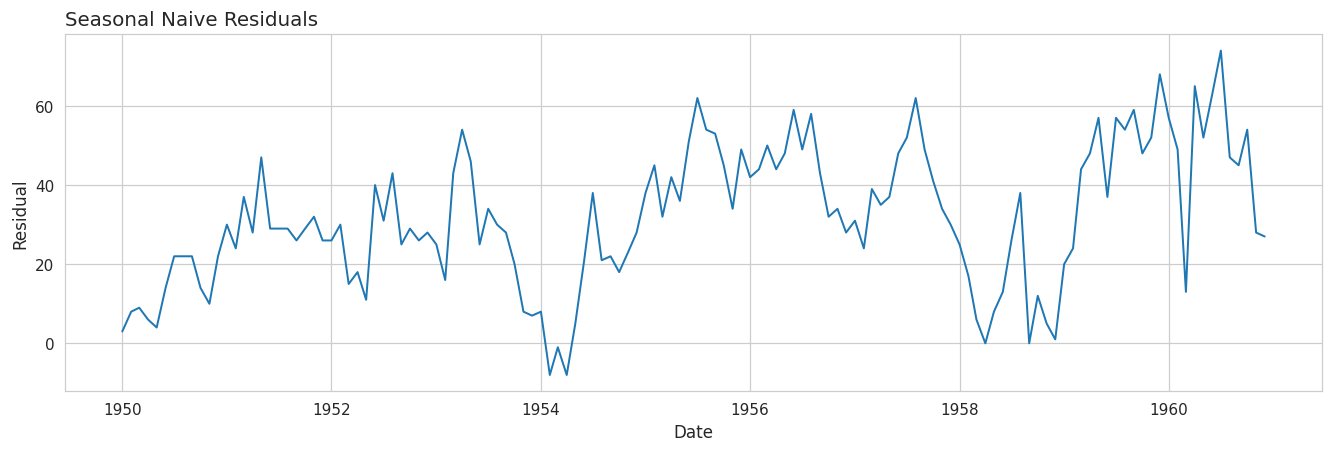

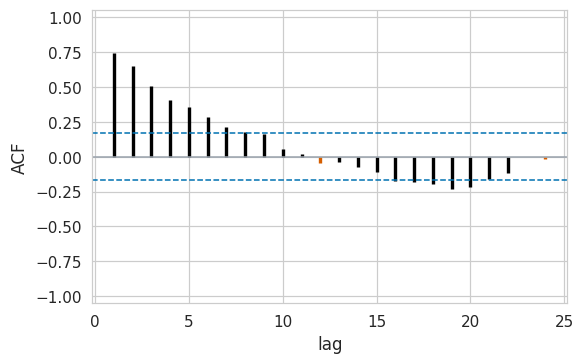

In [15]:

# Calculate seasonal naive residuals
resid_floor = df["y"] - df["y"].shift(SEASON_LENGTH)
resid_floor = resid_floor.dropna()

# Plot residuals
plt.figure(figsize=(12, 4))
plt.plot(df["ds"].iloc[SEASON_LENGTH:], resid_floor)
plt.title("Seasonal Naive Residuals")
plt.xlabel("Date")
plt.ylabel("Residual")
plt.show()

# Plot residual ACF
P.acf_plot(resid_floor, nlags=24, highlight_every=SEASON_LENGTH)
plt.show()



**2.1**  The residuals show that the seasonal naive model does not fully capture the upward trend. Significant ACF correlations indicate remaining structure, suggesting that a model accounting for both trend and autocorrelation may improve forecasts.


---
# 3. Your model: the framework

AutoGluon fits a zoo of models behind one call - every model in the zoo
below is a model you have met in this course. The install is large, so this
runs on Colab.

> Every cell in this section is **skip-guarded**: without `autogluon`
> installed it prints why and moves on, so the rest of the notebook still
> runs.

In [17]:
!pip install -q 'autogluon.timeseries'

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 1.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 274.4/274.4 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.7/90.7 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 248.4/248.4 kB 15.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.3/112.3 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 514.8/514.8 kB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.8/80.8 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 285.4/285.4 kB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 864.0/864.0 kB 37.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 38.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [18]:
import importlib.util

HAS_AG = importlib.util.find_spec("autogluon") is not None
if not HAS_AG:
    print("autogluon is not installed. On Colab, run this and re-run the cell:")
    print("    !pip install -q 'autogluon.timeseries'")
    print("\n(Takes a few minutes. A runtime reset wipes it.)")
else:
    print("autogluon is available")

autogluon is available


**3.1 The data conversion stays visible.** AutoGluon has its own
frame, its own column names, its own fit loop and its own leaderboard.
Writing it out by hand once is the point - the gap between two APIs doing
the same job is the thing to notice.

| | this course | AutoGluon |
|---|---|---|
| id column | `unique_id` | `item_id` |
| time column | `ds` | `timestamp` |
| value column | `y` | `target` (nameable) |
| frame | `pd.DataFrame` | `TimeSeriesDataFrame` |

AutoGluon uses different column names and a `TimeSeriesDataFrame` format. The data must be converted before training the models.


In [22]:
if HAS_AG:
    from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor

    # Long format to AutoGluon's long format: the same three columns, renamed.
    ag_long = df.rename(columns={"unique_id": "item_id", "ds": "timestamp"})
    tsdf = TimeSeriesDataFrame.from_data_frame(
        ag_long, id_column="item_id", timestamp_column="timestamp")

    # One 12-month holdout, cut the way AutoGluon expects.
    ag_train = tsdf.slice_by_timestep(None, -12)

    print(tsdf.head(3))
    print(f"\nfull: {len(tsdf)} rows   train: {len(ag_train)} rows")

                                               y
item_id                        timestamp        
Air passengers (Box & Jenkins) 1949-01-01  112.0
                               1949-02-01  118.0
                               1949-03-01  132.0

full: 144 rows   train: 132 rows


In [21]:
if HAS_AG:
    # Local models only - the same zoo this course taught, nothing neural.
    ZOO = {"Naive": {}, "SeasonalNaive": {}, "AutoETS": {},
           "AutoARIMA": {}, "Theta": {}}

    predictor = TimeSeriesPredictor(
        prediction_length=12, target="y", eval_metric="MASE",
        freq="MS", verbosity=1)
    predictor.fit(ag_train, hyperparameters=ZOO, time_limit=120)

In [23]:

# Display the leaderboard on the held-out months
leaderboard = predictor.leaderboard(tsdf)
leaderboard



,model,score_test,score_val,pred_time_test,pred_time_val,fit_time_marginal,fit_order
0,AutoARIMA,-0.608073,-1.575987,0.104985,0.166521,0.020907,5
1,WeightedEnsemble,-0.929514,-1.535792,0.207229,0.353287,0.367350,6
2,AutoETS,-1.169539,-1.554323,0.100828,0.184740,0.017983,4
3,Theta,-1.570881,-1.656513,0.015790,0.020073,0.017391,3
4,SeasonalNaive,-1.570881,-1.656513,0.008033,0.009345,0.017023,2
5,Naive,-2.495895,-3.196371,0.015788,0.010881,0.017312,1


All `score_val` values are negative. AutoARIMA performed best, while Naive performed worst. The leaderboard shows six models, including WeightedEnsemble.


**3.2 Read what it handed back.** What is the *sign* of `score_val`, and
what does the answer to "how many windows" mean for how much you should
trust this ranking? It decides what the next section does with this table.
And: does the shortlist agree with the shape you read in section 1?

**3.2** The `score_val` values are negative, and scores closer to zero are better. If the ranking is based on only one window, it may be unreliable. AutoARIMA performs best, and the shortlist includes models that can capture the trend and seasonality observed in Section 1.


---
# 4. The harness

The framework's ranking came from one internal split. One holdout is not a
ranking. So the shortlist goes through the rolling-origin harness: eight
origins, twelve months each, the whole distribution scored - and the floor
stays in the table.

In [24]:
sf_cv = StatsForecast(
    models=[SeasonalNaive(season_length=SEASON_LENGTH)],
    freq="MS", n_jobs=1)
cv = sf_cv.cross_validation(df=df, h=H, step_size=H, n_windows=8,
                            level=scoring.LEVELS)
cv.head()

,unique_id,ds,cutoff,y,SeasonalNaive,SeasonalNaive-lo-20,SeasonalNaive-lo-40,SeasonalNaive-lo-60,SeasonalNaive-lo-80,SeasonalNaive-lo-95,SeasonalNaive-hi-20,SeasonalNaive-hi-40,SeasonalNaive-hi-60,SeasonalNaive-hi-80,SeasonalNaive-hi-95
0,Air passengers (Box & Jenkins),1953-01-01,1952-12-01,196.0,171.0,164.48674,157.518271,149.362895,138.052796,120.6116,177.51326,184.481729,192.637105,203.947204,221.3884
1,Air passengers (Box & Jenkins),1953-02-01,1952-12-01,196.0,180.0,173.48674,166.518271,158.362895,147.052796,129.6116,186.51326,193.481729,201.637105,212.947204,230.3884
2,Air passengers (Box & Jenkins),1953-03-01,1952-12-01,236.0,193.0,186.48674,179.518271,171.362895,160.052796,142.6116,199.51326,206.481729,214.637105,225.947204,243.3884
3,Air passengers (Box & Jenkins),1953-04-01,1952-12-01,235.0,181.0,174.48674,167.518271,159.362895,148.052796,130.6116,187.51326,194.481729,202.637105,213.947204,231.3884
4,Air passengers (Box & Jenkins),1953-05-01,1952-12-01,229.0,183.0,176.48674,169.518271,161.362895,150.052796,132.6116,189.51326,196.481729,204.637105,215.947204,233.3884


In [26]:
mycv = mysf.cross_validation(
    df=df,
    h=H,
    step_size=H,
    n_windows=8,
    level=scoring.LEVELS
)

mycv.head()





,unique_id,ds,cutoff,y,AutoARIMA,AutoARIMA-lo-95,AutoARIMA-lo-80,AutoARIMA-lo-60,AutoARIMA-lo-40,AutoARIMA-lo-20,AutoARIMA-hi-20,AutoARIMA-hi-40,AutoARIMA-hi-60,AutoARIMA-hi-80,AutoARIMA-hi-95
0,Air passengers (Box & Jenkins),1953-01-01,1952-12-01,196.0,200.033960,186.129327,190.942209,194.063221,196.313689,198.236632,201.831289,203.754231,206.004700,209.125712,213.938594
1,Air passengers (Box & Jenkins),1953-02-01,1952-12-01,196.0,205.951260,191.099431,196.240171,199.573789,201.977561,204.031496,207.871024,209.924959,212.328732,215.662349,220.803089
2,Air passengers (Box & Jenkins),1953-03-01,1952-12-01,236.0,228.492818,210.220348,216.545092,220.646501,223.603906,226.130899,230.854738,233.381731,236.339136,240.440545,246.765289
3,Air passengers (Box & Jenkins),1953-04-01,1952-12-01,235.0,214.413179,194.752951,201.558047,205.970950,209.152963,211.871877,216.954482,219.673395,222.855409,227.268312,234.073408
4,Air passengers (Box & Jenkins),1953-05-01,1952-12-01,229.0,220.835055,199.055069,206.593888,211.482588,215.007685,218.019750,223.650360,226.662425,230.187522,235.076222,242.615041


In [28]:

floor_results = scoring.score_cv(cv, "SeasonalNaive", df)
model_results = scoring.score_cv(mycv, MY_NAME, df)

RESULTS = pd.DataFrame(
    [floor_results, model_results],
    index=["SeasonalNaive", MY_NAME]
)

RESULTS


,mase,rmsse,crps,coverage_80,mase_min,mase_max
SeasonalNaive,1.313310,1.245572,0.061603,0.510417,0.411584,1.958726
AutoARIMA,0.647227,0.683266,0.033870,0.697917,0.330149,1.593848


**4.1 Read the table.** Does the harness confirm the leaderboard's
shortlist, or does it move it? For each model: where does it beat the
floor, where does it lose, and on which of the three metrics? A model that
wins the point forecast and loses the distribution is a real result -
report both halves. And what does each model's 80% coverage say about its
band?

**4.1**  AutoARIMA performs better than SeasonalNaive on all three metrics: MASE, RMSSE, and CRPS. However, coverage is below 80% for both models: 51% for SeasonalNaive and 69.8% for AutoARIMA. This means their prediction intervals do not capture the actual values often enough, although AutoARIMA performs better overall.


---
# 5. The report

The notebook is evidence; the report is the claim. Two to three pages, for a
manager who will not open the notebook:

- **The recommendation.** Which model you would ship, in one sentence, and
  the one number that earns it.
- **The intervals.** How wide, what they covered, and whether the band is
  honest. Coverage is the check a band cannot do alone.
- **The residuals.** What the floor - and your model - missed. A residual
  ACF is a fact; a sentence about what it means is the deliverable.
- **One change.** A specific next step - data, driver, frequency, horizon -
  and what you expect it to do.

Rules: every number in the report comes out of this notebook; no number
that could not have come out of the harness counts; no leakage - a fold's
fit and its denominator use only data that fold was allowed to see.

**Optional, for extra credit.** The series is a total across origins, so a
driver is a modelling choice, not a lookup: pick a region and pull its
monthly mean temperature from a public weather archive (for example
Open-Meteo's historical API - free, no key), cache it next to the CSV, and
regress on it. That is dynamic regression - and the cross-validation
discipline still applies to the regression's residuals.

**Analysis Note:** The following analysis evaluates the time series patterns, compares SeasonalNaive and AutoARIMA using rolling-origin evaluation, examines prediction intervals and residuals, and identifies findings to support the final forecasting recommendation.


In [29]:

for name, results, prefix in [
    ("SeasonalNaive", cv, "SeasonalNaive"),
    ("AutoARIMA", mycv, "AutoARIMA")
]:
    lower = results[f"{prefix}-lo-80"]
    upper = results[f"{prefix}-hi-80"]

    print(f"{name}:")
    print(f"Mean 80% interval width: {(upper - lower).mean():.2f}")
    print(f"Median 80% interval width: {(upper - lower).median():.2f}")
    print()



SeasonalNaive:
Mean 80% interval width: 77.76
Median 80% interval width: 80.31

AutoARIMA:
Mean 80% interval width: 44.08
Median 80% interval width: 41.30



/tmp/ipykernel_2221/1482138411.py:20: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


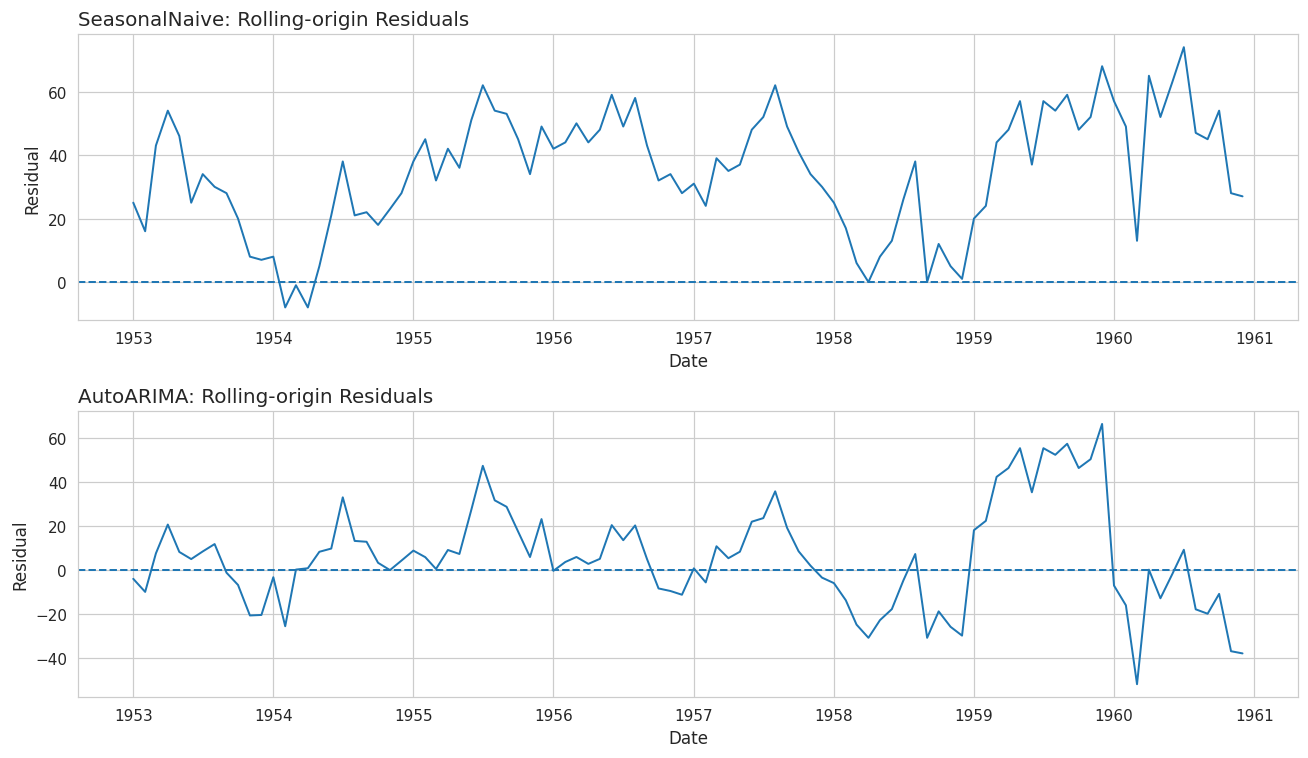

In [30]:

# Calculate out-of-sample residuals from rolling-origin forecasts
cv["residual"] = cv["y"] - cv["SeasonalNaive"]
mycv["residual"] = mycv["y"] - mycv["AutoARIMA"]

# Plot residuals over time
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

axes[0].plot(cv["ds"], cv["residual"])
axes[0].axhline(0, linestyle="--")
axes[0].set_title("SeasonalNaive: Rolling-origin Residuals")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Residual")

axes[1].plot(mycv["ds"], mycv["residual"])
axes[1].axhline(0, linestyle="--")
axes[1].set_title("AutoARIMA: Rolling-origin Residuals")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Residual")

plt.tight_layout()
plt.show()



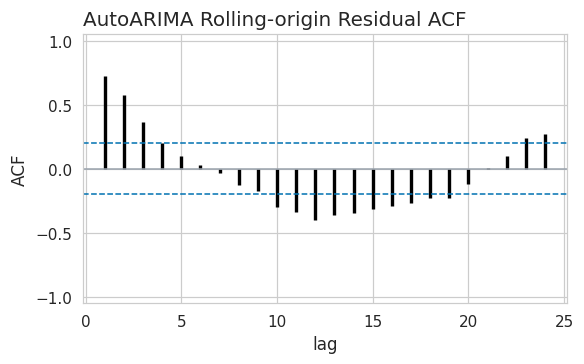

In [31]:

from statsforecast.utils import ConformalIntervals

# Examine autocorrelation in rolling-origin residuals
P.acf_plot(mycv["residual"], nlags=24)
plt.title("AutoARIMA Rolling-origin Residual ACF")
plt.show()

